# Извлечение именованных сущностей локальными языковыми моделями

Проверим, можно ли использовать готовую локальную LLM для NER без обучения.
Сравним Qwen 3 4B и более компактную Gemma 3 1B, исходную и уточнённую
инструкции, группировку по типам и список в порядке появления.

In [ ]:
import hashlib
import json
import math
import os
import platform
import random
import re
import time
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from typing import Annotated, Literal

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pydantic import BaseModel, ConfigDict, Field, ValidationError

## 1. Настройки и план эксперимента


In [ ]:
ROOT = Path.cwd()
DATA = ROOT / "data"
PREPARED = ROOT / "ner_prepared"
RESULTS = ROOT / "ner_results"
CACHE = RESULTS / "responses"
FIGURES = RESULTS / "figures"
for folder in (PREPARED, RESULTS, CACHE, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

In [ ]:
SEED = 42
N_SENTENCES = 100
N_DEV = 20
TYPES = ["PER", "LOC", "ORG", "MISC"]
MAIN_MODEL = "qwen3:4b-instruct"
SMALL_MODEL = "gemma3:1b"
OLLAMA_URL = os.getenv("OLLAMA_HOST", "http://ollama:11434")
OPTIONS = {"temperature": 0, "seed": SEED, "num_ctx": 4096,
           "num_predict": 512, "num_thread": 4}
REFRESH_RESPONSES = False
BOOTSTRAP_SAMPLES = 2000
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.2})

Выборка случайная, без отбора удобных примеров. Первые 20 случайно выбранных
предложений — **dev**: по ним уточняем инструкцию. Остальные 80 — **test**:
после фиксации инструкции используем их для итогового сравнения.
Это внутреннее разделение train, а не официальная test-часть CoNLL.

Сравниваем пять вариантов: Qwen с исходной группировкой, Qwen с уточнённой
группировкой, Qwen с уточнённым списком и Gemma с теми же двумя уточнёнными
форматами. Все варианты получают одинаковые предложения. Не обучаем модели.
Ответы сохраняем по одному; повторный запуск читает кэш с проверкой запроса
и идентификатора модели. Время в таблицах относится к исходной генерации.


In [ ]:
def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2),
                    encoding="utf-8")

In [ ]:
client = httpx.Client(base_url=OLLAMA_URL, timeout=600, trust_env=False)
environment = {
    "recorded_at": datetime.now(timezone.utc).isoformat(),
    "platform": platform.platform(), "architecture": platform.machine(),
    "logical_cpus": os.cpu_count(), "options": OPTIONS,
    "versions": {name: version(name) for name in
                 ["httpx", "pydantic", "numpy", "pandas", "matplotlib"]},
    "ollama": client.get("/api/version").json(),
}
save_json(RESULTS / "environment.json", environment)
pd.Series(environment)

recorded_at                                                                           2026-10-04T11:32:08.216559+00:00
platform                                                                 Linux-6.10.14-linuxkit-aarch64-with-glibc2.43
architecture                                                                                                   aarch64
logical_cpus                                                                                                         8
options                           {'temperature': 0, 'seed': 42, 'num_ctx': 4096, 'num_predict': 512, 'num_thread': 4}
versions        {'httpx': '0.28.1', 'pydantic': '2.13.5', 'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}
ollama                                                                                           {'version': '0.35.1'}
dtype: object

## 2. Выборка и эталонная разметка


In [ ]:
train = [json.loads(line) for line in
         (DATA / "train.json").read_text(encoding="utf-8").splitlines()]
label2id = json.loads((DATA / "label.json").read_text(encoding="utf-8"))
id2label = {value: key for key, value in label2id.items()}
data_hashes = {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
               for name in ["train.json", "valid.json", "test.json", "label.json"]}
assert all(len(row["tokens"]) == len(row["tags"]) for row in train)
assert all(tag in id2label for row in train for tag in row["tags"])
pd.Series({"train_sentences": len(train), **label2id})

train_sentences    14041
O                      0
B-ORG                  1
B-MISC                 2
B-PER                  3
I-PER                  4
B-LOC                  5
I-ORG                  6
I-MISC                 7
I-LOC                  8
dtype: int64

В train 14 041 предложение. Метки читаем из `label.json`: например,
`B-MISC` имеет номер 2. Нельзя подставлять порядок меток из другой версии
CoNLL: числовые значения не имеют самостоятельного смысла.


In [ ]:
def token_offsets(tokens):
    starts, ends, position = [], [], 0
    for token in tokens:
        starts.append(position)
        position += len(token)
        ends.append(position)
        position += 1
    return starts, ends

In [ ]:
def bio_to_entities(tokens, tags):
    starts, ends = token_offsets(tokens)
    entities, active, begin = [], None, 0
    labels = [id2label[tag] for tag in tags] + ["O"]
    for i, label in enumerate(labels):
        prefix, kind = label.split("-", 1) if label != "O" else ("O", None)
        if prefix == "I" and kind != active:
            raise ValueError(f"Некорректное продолжение BIO: {i}, {label}")
        if active and (prefix != "I" or kind != active):
            entities.append({"text": " ".join(tokens[begin:i]), "type": active,
                             "start": starts[begin], "end": ends[i - 1],
                             "token_start": begin, "token_end": i})
            active = None
        if prefix == "B":
            active, begin = kind, i
    return entities

In [ ]:
selected_ids = random.Random(SEED).sample(range(len(train)), N_SENTENCES)
inputs, gold = [], []
for position, source_id in enumerate(selected_ids):
    row = train[source_id]
    partition = "dev" if position < N_DEV else "test"
    item = {"id": source_id, "split": partition,
            "text": " ".join(row["tokens"]), "tokens": row["tokens"]}
    inputs.append(item)
    gold.append({"id": source_id, "split": partition,
                 "entities": bio_to_entities(row["tokens"], row["tags"])})
input_by_id = {item["id"]: item for item in inputs}
gold_by_id = {item["id"]: item["entities"] for item in gold}
assert len(set(selected_ids)) == N_SENTENCES

In [ ]:
save_json(PREPARED / "inputs.json", inputs)
save_json(PREPARED / "gold_entities.json", gold)
save_json(PREPARED / "selection.json", {"seed": SEED, "n_dev": N_DEV,
          "source_ids": selected_ids, "source_sha256": data_hashes})
for item in inputs:
    for entity in gold_by_id[item["id"]]:
        assert item["text"][entity["start"]:entity["end"]] == entity["text"]
print("100 текстов и эталон сохранены в разные файлы; границы проверены.")

100 текстов и эталон сохранены в разные файлы; границы проверены.


In [ ]:
sample_table = pd.DataFrame([
    {"id": item["id"], "split": item["split"],
     "tokens": len(item["tokens"]), "entities": len(gold_by_id[item["id"]]),
     **Counter(entity["type"] for entity in gold_by_id[item["id"]])}
    for item in inputs]).fillna(0)
sample_summary = sample_table.groupby("split").agg(
    sentences=("id", "count"), tokens=("tokens", "sum"),
    mean_length=("tokens", "mean"), max_length=("tokens", "max"),
    empty=("entities", lambda x: (x == 0).sum()),
    PER=("PER", "sum"), LOC=("LOC", "sum"),
    ORG=("ORG", "sum"), MISC=("MISC", "sum"))
display(sample_summary)
display(pd.DataFrame(gold_by_id[selected_ids[3]]))

,sentences,tokens,mean_length,max_length,empty,PER,LOC,ORG,MISC
split,,,,,,,,,
dev,20,320,16.0000,42,4,10.0,15.0,12.0,5.0
test,80,1199,14.9875,46,18,25.0,49.0,45.0,16.0


,text,type,start,end,token_start,token_end
0,Steve Weizman,PER,3,16,1,3
1,Copenhagen,LOC,19,29,4,5


В выборке 1 519 токенов и 177 упоминаний сущностей: LOC — 64,
ORG — 57, PER — 35, MISC — 21. Максимальная длина — 46 токенов.
На test приходится 135 сущностей, в том числе только 16 MISC; оценки редкого
класса будут нестабильными. В 22 из 100 предложений сущностей нет (4 dev и 18 test):
такие примеры проверяют, умеет ли модель возвращать пустой результат.
Строки со счётом и короткими именами сохраняем: это часть исходного корпуса.


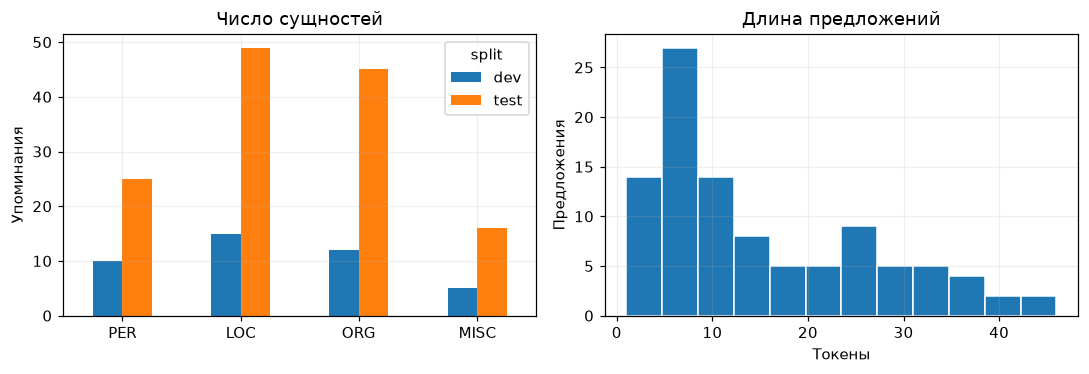

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sample_summary[TYPES].T.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Число сущностей", ylabel="Упоминания")
axes[1].hist(sample_table["tokens"], bins=12, edgecolor="white")
axes[1].set(title="Длина предложений", xlabel="Токены", ylabel="Предложения")
fig.tight_layout()
fig.savefig(FIGURES / "sample.png")
plt.show()

Текст восстанавливаем соединением токенов через пробел. Это сохраняет
однозначные границы для строгой оценки, но оставляет пробелы перед пунктуацией
и внутри сокращений (`'s`, `n't`). Модель должна копировать фрагмент именно
из этого текста. Ошибки написания не исправляем незаметно при подсчёте метрик.


## 3. Pydantic и Structured Output


In [ ]:
EntityType = Literal["PER", "LOC", "ORG", "MISC"]
EntityText = Annotated[str, Field(min_length=1)]

class StrictModel(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)

In [ ]:
class EntityGroups(StrictModel):
    PER: list[EntityText]
    LOC: list[EntityText]
    ORG: list[EntityText]
    MISC: list[EntityText]

class GroupedNER(StrictModel):
    entities: EntityGroups

GroupedNER.model_json_schema()

{'$defs': {'EntityGroups': {'additionalProperties': False,
   'properties': {'PER': {'items': {'minLength': 1, 'type': 'string'},
     'title': 'Per',
     'type': 'array'},
    'LOC': {'items': {'minLength': 1, 'type': 'string'},
     'title': 'Loc',
     'type': 'array'},
    'ORG': {'items': {'minLength': 1, 'type': 'string'},
     'title': 'Org',
     'type': 'array'},
    'MISC': {'items': {'minLength': 1, 'type': 'string'},
     'title': 'Misc',
     'type': 'array'}},
   'required': ['PER', 'LOC', 'ORG', 'MISC'],
   'title': 'EntityGroups',
   'type': 'object'}},
 'additionalProperties': False,
 'properties': {'entities': {'$ref': '#/$defs/EntityGroups'}},
 'required': ['entities'],
 'title': 'GroupedNER',
 'type': 'object'}

Все четыре группы обязательны, даже когда они пусты. Дополнительные поля
запрещены. JSON Schema передаём в `format` API Ollama, а ответ независимо
проверяем через `model_validate_json`. По [документации Ollama](https://docs.ollama.com/capabilities/structured-outputs)
схема ограничивает генерацию структуры. Она не проверяет, есть ли сущность
в исходном тексте, правильно ли выбран тип и не пропущено ли упоминание.


In [ ]:
class Entity(StrictModel):
    text: EntityText
    type: EntityType

class OrderedNER(StrictModel):
    entities: list[Entity]

SCHEMAS = {"grouped": GroupedNER, "ordered": OrderedNER}
OrderedNER.model_json_schema()


{'$defs': {'Entity': {'additionalProperties': False,
   'properties': {'text': {'minLength': 1, 'title': 'Text', 'type': 'string'},
    'type': {'enum': ['PER', 'LOC', 'ORG', 'MISC'],
     'title': 'Type',
     'type': 'string'}},
   'required': ['text', 'type'],
   'title': 'Entity',
   'type': 'object'}},
 'additionalProperties': False,
 'properties': {'entities': {'items': {'$ref': '#/$defs/Entity'},
   'title': 'Entities',
   'type': 'array'}},
 'required': ['entities'],
 'title': 'OrderedNER',
 'type': 'object'}

In [16]:
schema_checks = []
for raw in ['{"entities":{"PER":[],"LOC":[],"ORG":[],"MISC":[]}}',
            '{"entities":{"PER":[],"LOC":[],"ORG":[]}}',
            '{"entities":{"PER":[4],"LOC":[],"ORG":[],"MISC":[]}}']:
    try:
        GroupedNER.model_validate_json(raw)
        valid = True
    except ValidationError:
        valid = False
    schema_checks.append({"response": raw, "valid": valid})
display(pd.DataFrame(schema_checks))


,response,valid
0,"{""entities"":{""PER"":[],""LOC"":[],""ORG"":[],""MISC"":[]}}",True
1,"{""entities"":{""PER"":[],""LOC"":[],""ORG"":[]}}",False
2,"{""entities"":{""PER"":[4],""LOC"":[],""ORG"":[],""MISC"":[]}}",False


Пустые группы допустимы, пропущенная группа и число вместо строки отвергаются.
В эксперименте не будем исправлять ответ или повторять запрос ради получения
валидного JSON: отдельно измерим качество первого ответа. Ошибка запроса или
валидации означает пустое предсказание при оценке NER и уменьшает надёжность.


## 4. Получение и сохранение ответов


In [ ]:
def ensure_model(model):
    available = client.get("/api/tags").json()["models"]
    if not any(item["name"] == model for item in available):
        started = time.perf_counter()
        with client.stream("POST", "/api/pull", json={"model": model}) as response:
            response.raise_for_status()
            for line in response.iter_lines():
                event = json.loads(line)
                if "error" in event:
                    raise RuntimeError(event["error"])
        print(f"{model}: скачивание {time.perf_counter() - started:.1f} с")
    meta = next(item for item in client.get("/api/tags").json()["models"]
                if item["name"] == model)
    details = client.post("/api/show", json={"model": model})
    details.raise_for_status()
    return {**meta, "show": details.json()}

In [ ]:
model_metadata = {MAIN_MODEL: ensure_model(MAIN_MODEL)}
pd.Series({key: model_metadata[MAIN_MODEL][key]
                   for key in ["name", "digest", "size", "details"]})

name                                                                                                             qwen3:4b-instruct
digest                                                            0edcdef34593eac1aa2be9c7d06c432dcf81945adca5eca2f27662c18f168ba0
size                                                                                                                    2497293803
details    {'parent_model': '', 'format': 'gguf', 'family': 'qwen3', 'families': ['qwen3'], 'parameter_size': '4.0B', 'quantiza...
dtype: object

In [ ]:
BASE_PROMPT = """Extract all named entity mentions from the English sentence.
Use PER for people, LOC for locations, ORG for organizations, and MISC for
other named entities. Copy each entity exactly from the sentence.
Return only the JSON required by the schema, including empty lists.
Do not include explanations."""
GROUP_INSTRUCTION = "Group mentions by type. Keep repeated mentions."
ORDER_INSTRUCTION = "List every mention in its original order, including repetitions."

In [ ]:
def make_request(text, model, prompt, format_name):
    format_instruction = (GROUP_INSTRUCTION if format_name == "grouped"
                          else ORDER_INSTRUCTION)
    schema = SCHEMAS[format_name].model_json_schema()
    content = (prompt + "\n" + format_instruction + "\nJSON Schema:\n"
               + json.dumps(schema, ensure_ascii=False) + "\nSentence:\n" + text)
    return {"model": model, "messages": [{"role": "user", "content": content}],
            "format": schema, "stream": False, "options": OPTIONS,
            "keep_alive": "15m"}

In [ ]:
def response_path(request, item_id):
    signed = {"request": request,
              "digest": model_metadata[request["model"]]["digest"]}
    key = hashlib.sha256(json.dumps(signed, sort_keys=True).encode()).hexdigest()
    return CACHE / f"{item_id}_{key}.json"

In [ ]:
def generate_one(request, item):
    started = time.perf_counter()
    record = {"id": item["id"], "split": item["split"], "request": request,
              "model_digest": model_metadata[request["model"]]["digest"]}
    try:
        response = client.post("/api/chat", json=request)
        response.raise_for_status()
        record["response"] = response.json()
        if "error" in record["response"]:
            record["transport_error"] = record["response"]["error"]
    except (httpx.HTTPError, ValueError) as error:
        record["transport_error"] = str(error)
    record["wall_s"] = time.perf_counter() - started
    record["created_at"] = datetime.now(timezone.utc).isoformat()
    return record

In [ ]:
def run_experiment(name, model, prompt, format_name):
    records, cached = [], 0
    for position, item in enumerate(inputs, 1):
        request = make_request(item["text"], model, prompt, format_name)
        path = response_path(request, item["id"])
        if path.exists() and not REFRESH_RESPONSES:
            record = json.loads(path.read_text(encoding="utf-8"))
            assert record["request"] == request
            cached += 1
        else:
            record = generate_one(request, item)
            save_json(path.with_suffix(".tmp"), record)
            path.with_suffix(".tmp").replace(path)
        records.append({**record, "experiment": name, "format": format_name})
        if position % 10 == 0:
            print(f"{name}: {position}/{len(inputs)}", flush=True)
    save_json(RESULTS / f"{name}.json", records)
    if cached < len(records):
        save_json(RESULTS / f"{name}_resident.json", client.get("/api/ps").json())
    print(f"Из кэша: {cached}; новых запросов: {len(records) - cached}.")
    return records

Используем нативный [API Ollama](https://docs.ollama.com/api/chat): он возвращает
не только JSON, но и длительность загрузки, обработки запроса и генерации,
а также число токенов. Историю между предложениями не передаём.
В запрос входит инструкция, схема и текст; функция генерации не получает gold.
Ограничение 512 выходных токенов достаточно проверяем по `done_reason`.
Обрезанный ответ учитываем как сбой, а не восстанавливаем вручную.


## 5. Строгая оценка сущностей


Основные метрики — **entity-level Precision, Recall и micro-F1**.
TP требует полного совпадения границ упоминания и типа. Лишние упоминания — FP,
пропущенные — FN. Ошибочный тип даёт один FP и один FN. Macro-F1 и F1 по типам
помогают увидеть ошибки редкой MISC, которые скрывает усреднение по всем сущностям.
Дополнительно считаем долю полностью правильных предложений, корректность
структуры, незаземлённые фрагменты, повторы и нарушение порядка.
Строгое совпадение полного фрагмента соответствует принципу оценки
в [описании CoNLL-2003](https://aclanthology.org/W03-0419.pdf).

Строки ответа сопоставляем с точными непрерывными фрагментами исходного текста
на границах токенов. Повторные одинаковые строки связываем с ещё не использованным
вхождением слева направо в пределах того же типа; эталон при этом не используется.
Если модель назначает одному фрагменту несколько типов, все предсказания
оцениваем, сохраняя правильный TP и учитывая лишний тип как FP. Повторы сверх
числа вхождений тоже дают FP. Такие конфликты отмечаем отдельно. Схема без offsets
не позволяет однозначно определить, какое из одинаковых вхождений пропущено.
Это ограничение обоих исследуемых форматов, а не основание угадывать по gold.


`ungrounded` означает отсутствие точного фрагмента на границах токенов.
Строка может встречаться внутри токена (`Australian` в `league-Australian`)
и всё равно не соответствовать размеченному фрагменту. Такие случаи отделяем
от полностью отсутствующих строк в диагностике ошибок.


In [ ]:
def parse_response(record):
    raw = record.get("response", {}).get("message", {}).get("content", "")
    if record.get("transport_error"):
        return [], False, record["transport_error"]
    if record.get("response", {}).get("done_reason") == "length":
        return [], False, "Ответ оборван по лимиту генерации"
    try:
        parsed = SCHEMAS[record["format"]].model_validate_json(raw)
        if record["format"] == "ordered":
            entities = [item.model_dump() for item in parsed.entities]
        else:
            entities = [{"text": text, "type": kind} for kind in TYPES
                        for text in getattr(parsed.entities, kind)]
        return entities, True, ""
    except ValidationError as error:
        return [], False, str(error).splitlines()[0]

In [ ]:
def align_entities(entities, text):
    aligned, used, seen_spans = [], set(), set()
    for index, entity in enumerate(entities):
        pattern = r"(?<!\S)" + re.escape(entity["text"]) + r"(?!\S)"
        candidates = [(match.start(), match.end())
                      for match in re.finditer(pattern, text)]
        available = [span for span in candidates if (*span, entity["type"]) not in used]
        span = (available or candidates or [(-index - 1, -index - 1)])[0]
        duplicate = bool(candidates) and span in seen_spans
        if candidates:
            used.add((*span, entity["type"]))
            seen_spans.add(span)
        aligned.append({**entity, "start": span[0], "end": span[1],
                        "grounded": bool(candidates), "duplicate": duplicate,
                        "substring_present": entity["text"] in text})
    return aligned

In [ ]:
def entity_key(entity, with_type=True):
    span = (entity["start"], entity["end"])
    return (*span, entity["type"]) if with_type else span

def prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    return {"precision": precision, "recall": recall, "f1": f1}

In [ ]:
def score_one(record):
    entities, valid, validation_error = parse_response(record)
    predicted = align_entities(entities, input_by_id[record["id"]]["text"])
    expected = gold_by_id[record["id"]]
    p, g = Counter(map(entity_key, predicted)), Counter(map(entity_key, expected))
    tp, fp, fn = sum((p & g).values()), sum((p - g).values()), sum((g - p).values())
    positions = [item["start"] for item in predicted]
    ordered_eligible = record["format"] == "ordered" and len(predicted) >= 2
    checkable = all(item["grounded"] for item in predicted)
    order_ok = (checkable
                and all(a < b for a, b in zip(positions, positions[1:])))
    return {"id": record["id"], "split": record["split"],
            "experiment": record["experiment"], "tp": tp, "fp": fp, "fn": fn,
            "valid": valid, "validation_error": validation_error,
            "exact": valid and p == g, "ordered_eligible": ordered_eligible,
            "order_ok": order_ok, "sequence_exact": valid and
            list(map(entity_key, predicted)) == list(map(entity_key, expected)),
            "order_checkable": checkable,
            "predicted": predicted, "gold": expected, "wall_s": record["wall_s"],
            "ungrounded": sum(not item["grounded"] for item in predicted),
            "duplicates": sum(item["duplicate"] for item in predicted)}

In [ ]:
def summarize(scored, partition):
    rows = [row for row in scored if partition == "all" or row["split"] == partition]
    tp, fp, fn = [sum(row[key] for row in rows) for key in ["tp", "fp", "fn"]]
    eligible = [row for row in rows if row["ordered_eligible"]]
    return {"split": partition, "n": len(rows), "tp": tp, "fp": fp, "fn": fn,
            **prf(tp, fp, fn), "valid_rate": np.mean([row["valid"] for row in rows]),
            "sentence_exact": np.mean([row["exact"] for row in rows]),
            "order_n": len(eligible), "order_rate": np.mean(
                [row["order_ok"] for row in eligible]) if eligible else np.nan,
            "ungrounded": sum(row["ungrounded"] for row in rows),
            "duplicates": sum(row["duplicates"] for row in rows),
            "median_s": np.median([row["wall_s"] for row in rows])}

In [ ]:
def scores_by_type(scored, partition="test"):
    rows, results = [row for row in scored if partition == "all" or row["split"] == partition], []
    for kind in TYPES:
        tp = fp = fn = 0
        for row in rows:
            p = Counter(entity_key(e) for e in row["predicted"] if e["type"] == kind)
            g = Counter(entity_key(e) for e in row["gold"] if e["type"] == kind)
            tp += sum((p & g).values())
            fp += sum((p - g).values())
            fn += sum((g - p).values())
        results.append({"type": kind, "support": tp + fn,
                        "tp": tp, "fp": fp, "fn": fn, **prf(tp, fp, fn)})
    return pd.DataFrame(results)

In [ ]:
synthetic_text = "Alex met Alex in Rome ."
synthetic_gold = bio_to_entities(
    synthetic_text.split(), [label2id[tag] for tag in
                            ["B-PER", "O", "B-PER", "O", "B-LOC", "O"]])
synthetic_pred = align_entities([
    {"text": "Alex", "type": "PER"}, {"text": "Alex", "type": "PER"},
    {"text": "Rome", "type": "LOC"}], synthetic_text)
assert list(map(entity_key, synthetic_gold)) == list(map(entity_key, synthetic_pred))
assert not align_entities([{"text": "Paris", "type": "LOC"}], synthetic_text)[0]["grounded"]
assert prf(2, 1, 1)["f1"] == 2 / 3
print("BIO, повторные вхождения, незаземлённый фрагмент и F1 проверены.")

BIO, повторные вхождения, незаземлённый фрагмент и F1 проверены.


## 6. Исходная инструкция: Qwen и группировка


In [ ]:
conflict = align_entities([{"text": "Rome", "type": "ORG"},
                           {"text": "Rome", "type": "LOC"}], synthetic_text)
correct = Counter([(17, 21, "LOC")])
found = Counter(map(entity_key, conflict))
assert sum((found & correct).values()) == 1
assert sum((found - correct).values()) == 1
assert conflict[1]["duplicate"]
excess = align_entities([{"text": "Rome", "type": "LOC"}] * 2, synthetic_text)
assert Counter(map(entity_key, excess))[(17, 21, "LOC")] == 2
print("Конфликт типов и лишний повтор сохраняют TP и дают отдельный FP.")

Конфликт типов и лишний повтор сохраняют TP и дают отдельный FP.


In [ ]:
baseline_records = run_experiment("qwen_baseline_grouped", MAIN_MODEL,
                                  BASE_PROMPT, "grouped")
baseline_scored = [score_one(record) for record in baseline_records]

qwen_baseline_grouped: 10/100


qwen_baseline_grouped: 20/100


qwen_baseline_grouped: 30/100


qwen_baseline_grouped: 40/100


qwen_baseline_grouped: 50/100


...

qwen_baseline_grouped: 70/100


qwen_baseline_grouped: 80/100


qwen_baseline_grouped: 90/100


qwen_baseline_grouped: 100/100


Из кэша: 100; новых запросов: 0.


In [ ]:
display(pd.DataFrame([summarize(baseline_scored, "dev")]))
display(scores_by_type(baseline_scored, "dev"))

,split,n,tp,fp,fn,precision,recall,f1,valid_rate,sentence_exact,order_n,order_rate,ungrounded,duplicates,median_s
0,dev,20,26,53,16,0.329114,0.619048,0.429752,1.0,0.1,0,NaN,6,6,18.121607


,type,support,tp,fp,fn,precision,recall,f1
0,PER,10,8,4,2,0.666667,0.80,0.727273
1,LOC,15,15,14,0,0.517241,1.00,0.681818
2,ORG,12,3,6,9,0.333333,0.25,0.285714
3,MISC,5,0,29,5,0.000000,0.00,0.000000


На 20 dev-предложениях строгие Precision = 0,329,
Recall = 0,619, F1 = 0,430: 26 TP, 53 FP и 16 FN. При совпадении текста
не всегда совпадает тип; дубли между группами дополнительно ухудшают результат.
Главная проблема — смысловая избыточность ответа, а не формат JSON.
В MISC попадают обычные описания и числа, тогда как национальности пропускаются.


In [ ]:
dev_errors = [row for row in baseline_scored if row["split"] == "dev" and not row["exact"]]
display(pd.DataFrame([
    {"id": row["id"], "text": input_by_id[row["id"]]["text"],
     "gold": [(e["text"], e["type"]) for e in row["gold"]],
     "prediction": [(e["text"], e["type"]) for e in row["predicted"]]}
    for row in dev_errors]))
save_json(RESULTS / "baseline_dev_errors.json", dev_errors)

,id,text,gold,prediction
0,10476,CINCINNATI AT COLORADO,"[(CINCINNATI, ORG), (COLORADO, LOC)]","[(CINCINNATI, LOC), (COLORADO, LOC)]"
1,1824,"Relations with Russia , which is our main partner , have great importance , "" Kuchma said .","[(Russia, LOC), (Kuchma, PER)]","[(Kuchma, PER), (Russia, LOC), (Kuchma, MISC)]"
2,409,"He added : "" If no one asked , I never opened my mouth .",[],"[(He, PER), (I, PER)]"
3,12149,"-- Steve Weizman , Copenhagen newsroom +45 33969650","[(Steve Weizman, PER), (Copenhagen, LOC)]","[(Steve Weizman, PER), (Copenhagen, LOC), (Copenhagen newsroom, ORG), (+45 33969650, MISC)]"
4,4012,Graafschap Doetinchem 3 RKC Waalwijk 2,"[(Graafschap Doetinchem, ORG), (RKC Waalwijk, ORG)]","[(Graafschap, LOC), (Doetinchem, LOC), (Waalwijk, LOC), (RKC, ORG), (3, MISC), (2, MISC)]"
5,3657,Nottingham Forest 1 Middlesbrough 1,"[(Nottingham Forest, ORG), (Middlesbrough, ORG)]","[(Nottingham, LOC), (Middlesbrough, LOC), (Nottingham Forest, MISC), (Middlesbrough, MISC)]"
6,2286,"69 66 , Jose Maria Canizares -LPR- Spain -RPR- 67 68 , Paul Lawrie","[(Jose Maria Canizares, PER), (Spain, LOC), (Paul Lawrie, PER)]","[(Jose Maria Canizares, PER), (Paul Lawrie, PER), (Spain, LOC), (Jose Maria Canizares, ORG), (Paul Lawrie, ORG), (69..."
7,12066,"Hwa Kay plunges on rights issue , earnings .","[(Hwa Kay, PER)]","[(Hwa Kay, PER), (rights issue, MISC), (earnings, MISC)]"
8,1679,"But it was the bullish profit forecast for 1996/97 that took the spotlight in the market , with some analysts saying...",[],"[(analysts, PER), (1996/97, MISC), (20 percent, MISC)]"
9,11087,"He is being asked for the source of his information and who gave him this confidential document , "" one colleague to...","[(Reuters, ORG)]","[(Reuters, LOC), (Reuters, ORG), (one colleague, MISC)]"


Ошибки исходной инструкции видны даже при корректном JSON.
В `Graafschap Doetinchem 3 RKC Waalwijk 2` модель разбивает названия клубов,
выделяет города и добавляет счёт в MISC. В предложении без имён (`He added ...`)
возвращает местоимения как PER. В тексте о командире добавляет расстояния в MISC,
включает `General` в имя и пропускает `Russian` и `Chechen`.

Часть упоминаний оказывается сразу в нескольких группах: например,
`Kuchma` как PER и MISC, `Reuters` как LOC и ORG. Это нарушает требование одного
типа на упоминание. Отдельные ошибки связаны с условностями gold:
`Hwa Kay` размечено PER, `Ballybunion` — ORG; контекст предложения сам по себе
не всегда позволяет обосновать такой выбор. Gold сохраняем без исправлений.


## 7. Уточнение инструкции по dev


По ошибкам dev уточняем границы и типы, а не добавляем
правильные ответы из выборки. Явно исключаем местоимения, роли, числа, счёт,
измерения и маркеры скобок. Для MISC поясняем национальности и национальные
прилагательные; для ORG — спортивные клубы. Требуем одно непересекающееся
упоминание с одним типом, сохранение повторов и точного написания.
Смысл MISC сверяем с [описанием CoNLL-2003](https://aclanthology.org/W03-0419.pdf):
категория включает, в частности, национальные прилагательные и события.
Инструкция зафиксирована в `ner_results/prompt_lock.json` до анализа test.


In [ ]:
IMPROVED_PROMPT = """Extract every named entity mention using CoNLL-2003 conventions.
PER: names of individual people; exclude titles, roles and pronouns.
LOC: geographical places, including country and city names.
ORG: named organizations, companies, agencies, political groups and sports clubs.
MISC: other proper named entities, especially nationalities and nationality
adjectives, ethnic or religious names, and named events or works.
MISC is not a catch-all for ordinary words: dates, months, weekdays, numbers,
job titles and general descriptions are not named entities in this task.
Do not extract scores, phone numbers or measurements. Treat -LPR- and -RPR-
as punctuation, not entity names.
Use the context to distinguish a place from a sports club named after a place.
Copy the complete entity as an exact contiguous substring, preserving spaces,
case and punctuation. Do not expand abbreviations or resolve pronouns.
Extract only explicit mentions; do not infer names that are absent.
Use non-overlapping spans and one type per mention; keep each repeated occurrence.
Return only schema-compliant JSON, with empty lists where no entities occur."""
print(IMPROVED_PROMPT)

Extract every named entity mention using CoNLL-2003 conventions.
PER: names of individual people; exclude titles, roles and pronouns.
LOC: geographical places, including country and city names.
ORG: named organizations, companies, agencies, political groups and sports clubs.
MISC: other proper named entities, especially nationalities and nationality
adjectives, ethnic or religious names, and named events or works.
MISC is not a catch-all for ordinary words: dates, months, weekdays, numbers,
job titles and general descriptions are not named entities in this task.
Do not extract scores, phone numbers or measurements. Treat -LPR- and -RPR-
as punctuation, not entity names.
Use the context to distinguish a place from a sports club named after a place.
Copy the complete entity as an exact contiguous substring, preserving spaces,
case and punctuation. Do not expand abbreviations or resolve pronouns.
Extract only explicit mentions; do not infer names that are absent.
Use non-overlapping spans

In [ ]:
lock_path = RESULTS / "prompt_lock.json"
prompt_hash = hashlib.sha256(IMPROVED_PROMPT.encode()).hexdigest()
if lock_path.exists():
    prompt_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    assert prompt_lock["sha256"] == prompt_hash, "Инструкция изменена после фиксации"
else:
    save_json(lock_path, {"locked_at": datetime.now(timezone.utc).isoformat(),
        "prompt": IMPROVED_PROMPT, "sha256": prompt_hash,
        "dev_ids": [item["id"] for item in inputs if item["split"] == "dev"]})
print("Инструкция сверена с зафиксированной версией.")

Инструкция сверена с зафиксированной версией.


Инструкция фиксируется после просмотра dev. В ней нет эталонных ответов,
идентификаторов предложений или примеров из test. Test используем для проверки
переноса изменений. Уточнение задачи не гарантирует улучшение качества:
небольшая модель может хуже выполнять более длинную инструкцию.


In [ ]:
improved_grouped_records = run_experiment("qwen_improved_grouped", MAIN_MODEL,
                                         IMPROVED_PROMPT, "grouped")
improved_grouped_scored = [score_one(record) for record in improved_grouped_records]

qwen_improved_grouped: 10/100


qwen_improved_grouped: 20/100


qwen_improved_grouped: 30/100


qwen_improved_grouped: 40/100


qwen_improved_grouped: 50/100


...

qwen_improved_grouped: 70/100


qwen_improved_grouped: 80/100


qwen_improved_grouped: 90/100


qwen_improved_grouped: 100/100


Из кэша: 100; новых запросов: 0.


In [ ]:
prompt_comparison = pd.DataFrame([
    {"experiment": name, **summarize(scored, partition)}
    for name, scored in [("qwen_baseline_grouped", baseline_scored),
                         ("qwen_improved_grouped", improved_grouped_scored)]
    for partition in ["dev", "test"]])
prompt_comparison

,experiment,split,n,tp,fp,fn,precision,recall,f1,valid_rate,sentence_exact,order_n,order_rate,ungrounded,duplicates,median_s
0,qwen_baseline_grouped,dev,20,26,53,16,0.329114,0.619048,0.429752,1.0,0.1000,0,NaN,6,6,18.121607
1,qwen_baseline_grouped,test,80,88,250,47,0.260355,0.651852,0.372093,1.0,0.0875,0,NaN,23,24,17.625631
2,qwen_improved_grouped,dev,20,31,37,11,0.455882,0.738095,0.563636,1.0,0.1500,0,NaN,0,7,13.658069
3,qwen_improved_grouped,test,80,89,133,46,0.400901,0.659259,0.498599,1.0,0.2875,0,NaN,5,20,13.245821


На 80 test-предложениях исходная инструкция: Precision = 0,260, Recall = 0,652, F1 = 0,372. После уточнения: Precision = 0,401, Recall = 0,659, F1 = 0,499; изменение F1 — 0,127. Число FP изменилось с 250 до 133, FN — с 47 до 46. На dev F1 изменился с 0,430 до 0,564. Сравнение на test показывает перенос изменений за пределы примеров, использованных для уточнения. Это эффект всей новой инструкции; вклад каждого отдельного правила не измерялся.

На dev предложение с `He added` стало давать правильный пустой ответ, а `Russian` и `Chechen` теперь найдены как MISC. Однако телефон `+45 33969650` остаётся в MISC вопреки прямому запрету; уточнение инструкции не обеспечивает выполнения всех правил.


## 8. Список в порядке появления: Qwen


In [ ]:
improved_ordered_records = run_experiment("qwen_improved_ordered", MAIN_MODEL,
                                         IMPROVED_PROMPT, "ordered")
improved_ordered_scored = [score_one(record) for record in improved_ordered_records]

qwen_improved_ordered: 10/100


qwen_improved_ordered: 20/100


qwen_improved_ordered: 30/100


qwen_improved_ordered: 40/100


qwen_improved_ordered: 50/100


...

qwen_improved_ordered: 70/100


qwen_improved_ordered: 80/100


qwen_improved_ordered: 90/100


qwen_improved_ordered: 100/100


Из кэша: 100; новых запросов: 0.


In [ ]:
example_id = selected_ids[3]
print(input_by_id[example_id]["text"])
for records in [improved_grouped_records, improved_ordered_records]:
    example = next(record for record in records if record["id"] == example_id)
    print("\n" + example["format"])
    print(example["response"]["message"]["content"])

-- Steve Weizman , Copenhagen newsroom +45 33969650

grouped
{
  "entities": {
    "LOC": [
      "Copenhagen"
    ],
    "MISC": [
      "+45 33969650"
    ],
    "ORG": [
      "Copenhagen newsroom"
    ],
    "PER": [
      "Steve Weizman"
    ]
  }
}

ordered
{
  "entities": [
    {
      "text": "Steve Weizman",
      "type": "PER"
    },
    {
      "text": "Copenhagen",
      "type": "LOC"
    }
  ]
}


In [ ]:
display(pd.DataFrame([summarize(improved_ordered_scored, partition)
                      for partition in ["dev", "test"]]))
display(scores_by_type(improved_ordered_scored))
ordered_test = [row for row in improved_ordered_scored if row["split"] == "test"]
display(pd.Series({"exact_sequence_rate": np.mean([row["sequence_exact"] for row in ordered_test]),
    "checkable_order_n": sum(row["ordered_eligible"] and row["order_checkable"] for row in ordered_test),
    "strict_order_violations_n": sum(row["ordered_eligible"] and row["order_checkable"]
                              and not row["order_ok"] for row in ordered_test),
    "gold_has_2_entities": sum(len(row["gold"]) >= 2 for row in ordered_test),
    "predicted_has_2_entities": sum(row["ordered_eligible"] for row in ordered_test)}))

,split,n,tp,fp,fn,precision,recall,f1,valid_rate,sentence_exact,order_n,order_rate,ungrounded,duplicates,median_s
0,dev,20,28,18,14,0.608696,0.666667,0.636364,1.0,0.4500,13,0.923077,1,0,11.923522
1,test,80,77,40,58,0.658120,0.570370,0.611111,1.0,0.3125,32,0.875000,1,1,4.612336


,type,support,tp,fp,fn,precision,recall,f1
0,PER,25,21,1,4,0.954545,0.840000,0.893617
1,LOC,49,34,13,15,0.723404,0.693878,0.708333
2,ORG,45,19,10,26,0.655172,0.422222,0.513514
3,MISC,16,3,16,13,0.157895,0.187500,0.171429


exact_sequence_rate           0.3125
checkable_order_n            31.0000
strict_order_violations_n     3.0000
gold_has_2_entities          33.0000
predicted_has_2_entities     32.0000
dtype: float64

Список Qwen: Precision = 0,658, Recall = 0,570, F1 = 0,611. F1 отличается от группировки на 0,113. Среди 32 test-ответов с минимум двумя сущностями порядок успешно проверен в 28; ответов с инверсией — 3, с повтором соседней позиции — 1, с непроверяемыми позициями — 1. Полная последовательность совпала с gold в 25/80 предложениях. Правильный порядок не компенсирует пропуски или неверные типы; пустые и одноэлементные списки в проверку порядка не входят.


In [ ]:
order_errors = [row for row in improved_ordered_scored
                if row["split"] == "test" and row["ordered_eligible"] and not row["order_ok"]]
display(pd.DataFrame([{"id": row["id"], "text": input_by_id[row["id"]]["text"],
    "cause": "inversion_or_repeat" if row["order_checkable"] else "unverifiable",
    "prediction": [(e["text"], e["type"], e["start"]) for e in row["predicted"]]}
    for row in order_errors]))
print(f"Нарушения порядка/непроверяемые позиции: {len(order_errors)}.")

,id,text,cause,prediction
0,13261,Southern California Edison Co said it expected two 220 kilovolt -LPR- KV -RPR- power lines in southern California to...,inversion_or_repeat,"[(Southern California Edison Co, ORG, 0), (southern California, LOC, 94), (southern California, LOC, 94), (Los Angel..."
1,106,""" The message that we sent to -LPR- Syrian President Hafez al- -RPR- Assad is that Israel is ready at any time witho...",inversion_or_repeat,"[(Syrian President Hafez al-, PER, 36), (Hafez al-, PER, 53), (Assad, PER, 69), (David Levy, PER, 190), (Israel, LOC..."
2,13202,- Opposition leader Nawaz Sharif renewed a pledge to oust the Pakistan People 's Party government headed by Prime Mi...,unverifiable,"[(Nawaz Sharif, PER, 20), (Pakistan People's Party, ORG, -2), (Benazir Bhutto, PER, 123)]"
3,10299,"Partizan -LPR- Yugoslavia -RPR- , Alba -LPR- Germany -RPR- , Dinamo -LPR- Russia -RPR- and Benetton -LPR- Italy -RPR...",inversion_or_repeat,"[(Partizan, ORG, 0), (Alba, ORG, 34), (Dinamo, ORG, 61), (Benetton, ORG, 91), (Yugoslavia, LOC, 15), (Germany, LOC, ..."


Нарушения порядка/непроверяемые позиции: 4.


Проверяем порядок **до любой сортировки**. `order_rate` — доля ответов с минимум
двумя предсказаниями, в которых все фрагменты найдены и позиции строго возрастают.
Списки длиной 0–1 не проверяют способность упорядочивать. Монотонный неполный
список может иметь правильный порядок, но плохую полноту. Поэтому рядом приведена
доля полного совпадения последовательности с gold. Незаземлённые строки делают
порядок непроверяемым и не засчитываются как успешный порядок.


**Группировка** удобна для списков людей, мест и организаций и агрегации по типам.
Схема компактная, тип записывается один раз на группу, пустые группы задают
предсказуемые ключи. Общий порядок между типами потерян; восстановление позиций
по строкам неоднозначно при повторных упоминаниях.

**Единый список** удобен для последовательной обработки, подсветки, привязки
сущностей к контексту и построения связей. Тип повторяется для каждого объекта,
ответ может быть длиннее, а порядок приходится проверять программно.
Для production в оба формата стоит добавить проверяемые `start`/`end` и
идентификатор упоминания. Здесь offsets не выдаёт модель: такой третий формат
потребовал бы отдельного эксперимента. Ни один из двух форматов сам по себе
не устраняет смысловые ошибки NER.


## 9. Компактная альтернативная модель: Gemma 3 1B


Выбираем `gemma3:1b` как попытку уменьшить затраты, а не только увеличить число
параметров. [Карточка Ollama](https://ollama.com/library/gemma3:1b) указывает
около 1 млрд параметров и Q4_K_M, веса около 815 МБ.
У [Qwen 3 4B Instruct](https://ollama.com/library/qwen3:4b-instruct) около
4,02 млрд параметров, Q4_K_M и 2,5 ГБ. Сравниваем разные семьи и размеры;
отдельный эффект количества параметров этим опытом не определяется.


In [ ]:
client.post("/api/generate", json={"model": MAIN_MODEL, "keep_alive": 0}).raise_for_status()
model_metadata[SMALL_MODEL] = ensure_model(SMALL_MODEL)
display(pd.Series({key: model_metadata[SMALL_MODEL][key]
                   for key in ["name", "digest", "size", "details"]}))

name                                                                                                                     gemma3:1b
digest                                                            8648f39daa8fbf5b18c7b4e6a8fb4990c692751d49917417b8842ca5758e7ffc
size                                                                                                                     815319791
details    {'parent_model': '', 'format': 'gguf', 'family': 'gemma3', 'families': ['gemma3'], 'parameter_size': '999.89M', 'qua...
dtype: object

In [ ]:
small_grouped_records = run_experiment("gemma_improved_grouped", SMALL_MODEL,
                                      IMPROVED_PROMPT, "grouped")
small_grouped_scored = [score_one(record) for record in small_grouped_records]

gemma_improved_grouped: 10/100


gemma_improved_grouped: 20/100


gemma_improved_grouped: 30/100


gemma_improved_grouped: 40/100


gemma_improved_grouped: 50/100


...

gemma_improved_grouped: 70/100


gemma_improved_grouped: 80/100


gemma_improved_grouped: 90/100


gemma_improved_grouped: 100/100


Из кэша: 100; новых запросов: 0.


In [ ]:
small_ordered_records = run_experiment("gemma_improved_ordered", SMALL_MODEL,
                                      IMPROVED_PROMPT, "ordered")
small_ordered_scored = [score_one(record) for record in small_ordered_records]

gemma_improved_ordered: 10/100


gemma_improved_ordered: 20/100


gemma_improved_ordered: 30/100


gemma_improved_ordered: 40/100


gemma_improved_ordered: 50/100


...

gemma_improved_ordered: 70/100


gemma_improved_ordered: 80/100


gemma_improved_ordered: 90/100


gemma_improved_ordered: 100/100


Из кэша: 100; новых запросов: 0.


In [ ]:
all_records = {"qwen_baseline_grouped": baseline_records,
    "qwen_improved_grouped": improved_grouped_records,
    "qwen_improved_ordered": improved_ordered_records,
    "gemma_improved_grouped": small_grouped_records,
    "gemma_improved_ordered": small_ordered_records}

In [ ]:
all_scored = {"qwen_baseline_grouped": baseline_scored,
    "qwen_improved_grouped": improved_grouped_scored,
    "qwen_improved_ordered": improved_ordered_scored,
    "gemma_improved_grouped": small_grouped_scored,
    "gemma_improved_ordered": small_ordered_scored}

In [ ]:
summary = pd.DataFrame([
    {"experiment": name, **summarize(scored, partition),
     "macro_f1": scores_by_type(scored, partition)["f1"].mean()}
    for name, scored in all_scored.items() for partition in ["dev", "test", "all"]])
type_metrics = pd.concat([
    scores_by_type(scored).assign(experiment=name)
    for name, scored in all_scored.items()], ignore_index=True)
display(summary.loc[summary["split"] == "test", ["experiment", "n", "tp", "fp", "fn",
    "precision", "recall", "f1", "macro_f1", "valid_rate", "sentence_exact", "median_s"]])
display(type_metrics)

display(Markdown("Описание всех 100 предложений (включая dev):"))
display(summary.loc[summary["split"] == "all", ["experiment", "n",
    "precision", "recall", "f1", "valid_rate"]])

,experiment,n,tp,fp,fn,precision,recall,f1,macro_f1,valid_rate,sentence_exact,median_s
1,qwen_baseline_grouped,80,88,250,47,0.260355,0.651852,0.372093,0.483202,1.0000,0.0875,17.625631
4,qwen_improved_grouped,80,89,133,46,0.400901,0.659259,0.498599,0.528464,1.0000,0.2875,13.245821
7,qwen_improved_ordered,80,77,40,58,0.658120,0.570370,0.611111,0.571723,1.0000,0.3125,4.612336
10,gemma_improved_grouped,80,73,270,62,0.212828,0.540741,0.305439,0.258514,1.0000,0.0125,14.615568
13,gemma_improved_ordered,80,71,318,64,0.182519,0.525926,0.270992,0.308349,0.9875,0.0125,14.853076


,type,support,tp,fp,fn,precision,recall,f1,experiment
0,PER,25,24,8,1,0.750000,0.960000,0.842105,qwen_baseline_grouped
1,LOC,49,43,48,6,0.472527,0.877551,0.614286,qwen_baseline_grouped
2,ORG,45,16,14,29,0.533333,0.355556,0.426667,qwen_baseline_grouped
3,MISC,16,5,180,11,0.027027,0.312500,0.049751,qwen_baseline_grouped
4,PER,25,22,2,3,0.916667,0.880000,0.897959,qwen_improved_grouped
5,LOC,49,44,40,5,0.523810,0.897959,0.661654,qwen_improved_grouped
6,ORG,45,19,17,26,0.527778,0.422222,0.469136,qwen_improved_grouped
7,MISC,16,4,74,12,0.051282,0.250000,0.085106,qwen_improved_grouped
8,PER,25,21,1,4,0.954545,0.840000,0.893617,qwen_improved_ordered
9,LOC,49,34,13,15,0.723404,0.693878,0.708333,qwen_improved_ordered


Описание всех 100 предложений (включая dev):

,experiment,n,precision,recall,f1,valid_rate
2,qwen_baseline_grouped,100,0.273381,0.644068,0.383838,1.00
5,qwen_improved_grouped,100,0.413793,0.677966,0.513919,1.00
8,qwen_improved_ordered,100,0.644172,0.593220,0.617647,1.00
11,gemma_improved_grouped,100,0.217799,0.525424,0.307947,1.00
14,gemma_improved_ordered,100,0.197980,0.553672,0.291667,0.99


По dev выбрана конфигурация `qwen_improved_ordered`: dev F1 = 0,636, test F1 = 0,611. Лидер test — `qwen_improved_ordered` с F1 = 0,611; это описание итоговой таблицы, а не повторная настройка по test. У компактной Gemma test F1 = 0,305 при группировке и 0,271 при списке. Размер модели и семейство меняются одновременно, поэтому различие нельзя объяснить только числом параметров. Для всех 100 предложений F1 выбранной конфигурации = 0,618; это описательная оценка с включением dev, основной независимый результат относится к 80 test-предложениям.


In [ ]:
reliability = pd.DataFrame([
    {"experiment": name, "valid": sum(row["valid"] for row in scored),
     "total": len(scored), "ungrounded": sum(row["ungrounded"] for row in scored),
     "duplicates": sum(row["duplicates"] for row in scored),
     "order_test_n": summarize(scored, "test")["order_n"],
     "order_test_rate": summarize(scored, "test")["order_rate"]}
    for name, scored in all_scored.items()])
reliability

,experiment,valid,total,ungrounded,duplicates,order_test_n,order_test_rate
0,qwen_baseline_grouped,100,100,29,30,0,NaN
1,qwen_improved_grouped,100,100,5,27,0,NaN
2,qwen_improved_ordered,100,100,2,1,32,0.875000
3,gemma_improved_grouped,100,100,63,56,0,NaN
4,gemma_improved_ordered,99,100,24,23,79,0.544304


Число валидных первых ответов из 100: `qwen_baseline_grouped` — 100; `qwen_improved_grouped` — 100; `qwen_improved_ordered` — 100; `gemma_improved_grouped` — 100; `gemma_improved_ordered` — 99. Ответ с обрывом или ошибкой схемы не восстанавливался. Даже успешно проверенный JSON может содержать неверный тип, лишнее упоминание или строку вне текста. Нужны независимая валидация структуры и проверка привязки к тексту; эти проверки не доказывают содержательную правильность NER.


In [ ]:
empty_quality = []
for name, scored in all_scored.items():
    empty = [row for row in scored if row["split"] == "test" and not row["gold"]]
    nonempty = [row for row in scored if row["split"] == "test" and row["gold"]]
    empty_quality.append({"experiment": name, "empty_n": len(empty),
        "empty_with_extra": sum(bool(row["predicted"]) for row in empty),
        "nonempty_exact": np.mean([row["exact"] for row in nonempty]),
        "invalid_n": sum(not row["valid"] for row in scored)})
pd.DataFrame(empty_quality)

,experiment,empty_n,empty_with_extra,nonempty_exact,invalid_n
0,qwen_baseline_grouped,18,11,0.000000,0
1,qwen_improved_grouped,18,1,0.096774,0
2,qwen_improved_ordered,18,0,0.112903,0
3,gemma_improved_grouped,18,18,0.016129,0
4,gemma_improved_ordered,18,17,0.016129,1


В test 18 предложений без эталонных сущностей. Лишние предсказания появились в `qwen_baseline_grouped` — 11/18; `qwen_improved_grouped` — 1/18; `qwen_improved_ordered` — 0/18; `gemma_improved_grouped` — 18/18; `gemma_improved_ordered` — 17/18. Пустой ответ здесь правильный, но на предложениях с сущностями он означает пропуски. Невалидный ответ отдельно учитывается как сбой и не считается корректным пустым JSON.


## 10. Ошибки, MISC и надёжность результата


In [ ]:
def error_details(row):
    extra, missing = [], list(row["gold"])
    for predicted in row["predicted"]:
        match = next((e for e in missing if entity_key(e) == entity_key(predicted)), None)
        if match:
            missing.remove(match)
        else:
            extra.append(predicted)
    errors = []
    for predicted in extra:
        same = next((e for e in missing if entity_key(e, False) ==
                     entity_key(predicted, False)), None)
        overlap = next((e for e in missing if predicted["start"] >= 0 and
                        max(e["start"], predicted["start"]) <
                        min(e["end"], predicted["end"])), None)
        expected = same or overlap
        kind = ("wrong_type" if same else "boundary" if overlap else
                "duplicate" if predicted["duplicate"] else
                "token_boundary" if not predicted["grounded"] and predicted["substring_present"]
                else "ungrounded" if not predicted["grounded"] else "extra")
        if expected:
            missing.remove(expected)
        errors.append({"kind": kind, "prediction": predicted, "gold": expected})
    errors.extend({"kind": "missing", "prediction": None, "gold": e} for e in missing)
    return errors

In [ ]:
error_rows = []
for name, scored in all_scored.items():
    for row in scored:
        for error in error_details(row):
            error_rows.append({"experiment": name, "split": row["split"],
                "id": row["id"], "text": input_by_id[row["id"]]["text"],
                "kind": error["kind"], "gold": error["gold"],
                "prediction": error["prediction"]})
errors = pd.DataFrame(error_rows)
display(pd.crosstab(errors.loc[errors["split"] == "test", "experiment"],
                    errors.loc[errors["split"] == "test", "kind"]))
save_json(RESULTS / "error_analysis.json", error_rows)

kind,boundary,duplicate,extra,missing,token_boundary,ungrounded,wrong_type
experiment,,,,,,,
gemma_improved_grouped,19,21,151,18,9,45,25
gemma_improved_ordered,18,17,232,16,7,14,30
qwen_baseline_grouped,16,20,165,5,21,2,26
qwen_improved_grouped,12,16,78,12,3,2,22
qwen_improved_ordered,11,1,16,36,0,1,11


У выбранного по dev варианта `qwen_improved_ordered` диагностические ошибки на test: missing — 36, extra — 16, wrong_type — 11, boundary — 11, duplicate — 1, ungrounded — 1. Неверный тип и несовпадение границ дают одновременно FP и FN. В диагностической таблице такая пара показана одной ошибкой, поэтому сумма столбцов не равна FP + FN. Повтор или назначение нескольких типов одному фрагменту не удаляется перед оценкой.


In [ ]:
misc_gold = pd.DataFrame([
    {"id": item["id"], "split": item["split"], "entity": entity["text"],
     "text": item["text"]}
    for item in inputs for entity in gold_by_id[item["id"]]
    if entity["type"] == "MISC"])
misc_gold

,id,split,entity,text
0,8935,dev,Russian,"The Russian army commander in the region , General Vyacheslav Tikhomirov , arrived at the rebel-held village of Novy..."
1,8935,dev,Chechen,"The Russian army commander in the region , General Vyacheslav Tikhomirov , arrived at the rebel-held village of Novy..."
2,9674,dev,Arab,"He told Reuters the reason was his own front-page editorial , entitled "" A Chronic Mental Illness "" in which he atta..."
3,9674,dev,Israeli,"He told Reuters the reason was his own front-page editorial , entitled "" A Chronic Mental Illness "" in which he atta..."
4,1535,dev,Irish,Clinton made a triumphant Irish tour to back a Northern Ireland peace process but was forced to drop Ballybunion fro...
5,10647,test,Euro 96,"Euro 96 star Vladimir Smicer of the Czech Republic scored at the last second for Lens , allowing them to retain the ..."
6,10647,test,French,"Euro 96 star Vladimir Smicer of the Czech Republic scored at the last second for Lens , allowing them to retain the ..."
7,11490,test,International Petroleum Encyclopedia,The former Soviet Union was displaced as contractor of the potentially rich Shabwa oilfields once it collapsed in De...
8,8928,test,Bosnian Serb,"The Bosnian Serb cabinet , in a letter to the OSCE , said on Monday that any delay of local elections would be "" a d..."
9,9654,test,DEM,CALL C 98.00 PCT 0.47 DEM 3.30 PCT 202.90 X


В этих 100 предложениях 21 MISC-упоминание: 12 национальных,
этнических и географических определений (например, `Russian`, `Bosnian Serb`,
`Swiss`), 5 названий соревнований или лиг (`Euro 96`, `U.S. Open`, `MAJOR LEAGUE`,
`British Masters`, `TOSHIBA CLASSIC`), название справочника
`International Petroleum Encyclopedia`, модель автомобиля `Subaru Impreza` и
2 валютных обозначения (`DEM`, `A$`). Слитный токен `league-Australian`
размечен целиком: выделение только `Australian` не совпадает с gold.

MISC объединяет разные смысловые семейства и не означает «всё необычное».
На dev все 5 MISC — определения национальности/этничности, тогда как 9 из 16
test-упоминаний относятся к другим семействам. Поэтому уточнение только
национальностей не может заранее обеспечить полноту MISC на test.
Рассматриваем именно фактическую разметку корпуса, включая её условности.


In [ ]:
misc_metrics = type_metrics[type_metrics["type"] == "MISC"].copy()
display(misc_metrics)
misc_errors = errors[(errors["split"] == "test") & errors.apply(
    lambda row: (row["gold"] or {}).get("type") == "MISC" or
                (row["prediction"] or {}).get("type") == "MISC", axis=1)]
misc_errors[["experiment", "id", "kind", "gold", "prediction"]]

,type,support,tp,fp,fn,precision,recall,f1,experiment
3,MISC,16,5,180,11,0.027027,0.3125,0.049751,qwen_baseline_grouped
7,MISC,16,4,74,12,0.051282,0.2500,0.085106,qwen_improved_grouped
11,MISC,16,3,16,13,0.157895,0.1875,0.171429,qwen_improved_ordered
15,MISC,16,1,39,15,0.025000,0.0625,0.035714,gemma_improved_grouped
19,MISC,16,2,172,14,0.011494,0.1250,0.021053,gemma_improved_ordered


,experiment,id,kind,gold,prediction
56,qwen_baseline_grouped,3811,token_boundary,None,"{'text': 'LPR', 'type': 'MISC', 'start': -1, 'end': -1, 'grounded': False, 'duplicate': False, 'substring_present': ..."
57,qwen_baseline_grouped,3811,extra,None,"{'text': 'won', 'type': 'MISC', 'start': 60, 'end': 63, 'grounded': True, 'duplicate': False, 'substring_present': T..."
60,qwen_baseline_grouped,8279,extra,None,"{'text': '1', 'type': 'MISC', 'start': 10, 'end': 11, 'grounded': True, 'duplicate': False, 'substring_present': True}"
61,qwen_baseline_grouped,8279,extra,None,"{'text': '2', 'type': 'MISC', 'start': 22, 'end': 23, 'grounded': True, 'duplicate': False, 'substring_present': True}"
64,qwen_baseline_grouped,9863,duplicate,None,"{'text': 'Commodities Desk', 'type': 'MISC', 'start': 9, 'end': 25, 'grounded': True, 'duplicate': True, 'substring_..."
...,...,...,...,...,...
1351,gemma_improved_ordered,10980,extra,None,"{'text': 'crude', 'type': 'MISC', 'start': 38, 'end': 43, 'grounded': True, 'duplicate': False, 'substring_present':..."
1352,gemma_improved_ordered,10980,extra,None,"{'text': 'Oct', 'type': 'MISC', 'start': 48, 'end': 51, 'grounded': True, 'duplicate': False, 'substring_present': T..."
1355,gemma_improved_ordered,4374,extra,None,"{'text': 'Saturday', 'type': 'MISC', 'start': 107, 'end': 115, 'grounded': True, 'duplicate': False, 'substring_pres..."
1358,gemma_improved_ordered,11498,wrong_type,"{'text': 'African', 'type': 'MISC', 'start': 14, 'end': 21, 'token_start': 3, 'token_end': 4}","{'text': 'African', 'type': 'LOC', 'start': 14, 'end': 21, 'grounded': True, 'duplicate': False, 'substring_present'..."


На 80 test-предложениях F1 категории MISC: Qwen исходная группировка — 0,050,
Qwen уточнённая группировка — 0,085, Qwen список — 0,171; Gemma группировка —
0,036, Gemma список — 0,021. Даже лучший вариант нашёл только 3 из 16 MISC
при 16 FP: Precision = 0,158 и Recall = 0,188. Рост общего F1 не означает,
что редкая категория стала пригодна для автоматического извлечения.

У Qwen со списком три точных совпадения — `Israeli`, `Bosnian Serb`, `African`.
Другие национальности тоже создают проблемы: вместо `French` возвращается
`French soccer league`, вместо `Swiss` — `Swiss francs`. Названия соревнований
`U.S. Open`, `British Masters`, `TOSHIBA CLASSIC`, `MAJOR LEAGUE` пропущены;
в предложении о футболе пропущено `Euro 96`. `Subaru Impreza` и
`International Petroleum Encyclopedia` получили ORG вместо MISC.
`DEM` пропущено, а вместо `A$` выделено `A$ 4.3 million`. В MISC по-прежнему
ошибочно добавляются даты, дни недели и обычные описания.

Для PER обычно достаточно различить имя человека и роль; в MISC приходится
различать национальности, события, произведения, продукты и валютные символы,
следуя условностям корпуса. Например, `GACETA DE LOS NEGOCIOS` размечено ORG,
а название справочника — MISC: правило «все публикации одного типа» неверно.
В отличие от простой опечатки, такую ошибку нельзя устранить проверкой JSON
или наличия строки в тексте. Для следующего исследования нужны более точные
правила и dev-примеры разных семейств MISC, затем новая независимая проверка.


In [ ]:
best_name = summary.loc[summary["split"] == "dev"].sort_values(
    ["f1", "median_s"], ascending=[False, True]).iloc[0]["experiment"]
confusion_rows = []
for row in all_scored[best_name]:
    if row["split"] != "test":
        continue
    for error in error_details(row):
        confusion_rows.append({"gold": (error["gold"] or {}).get("type", "EXTRA"),
            "predicted": (error["prediction"] or {}).get("type", "MISSED")})
confusion = pd.crosstab(pd.DataFrame(confusion_rows)["gold"],
                       pd.DataFrame(confusion_rows)["predicted"])
display(Markdown(f"Конфигурация, выбранная по dev: **{best_name}**."))
display(confusion)

Конфигурация, выбранная по dev: **qwen_improved_ordered**.

predicted,LOC,MISC,MISSED,ORG,PER
gold,,,,,
EXTRA,2,11,0,5,0
LOC,3,1,8,3,0
MISC,0,3,7,2,1
ORG,8,1,17,0,0
PER,0,0,4,0,0


Таблица показывает **только ошибки**, включая пропуски и лишние сущности.
Тип сопоставляем по точным границам или пересечению ошибочных границ.
Это диагностическая таблица, а не обычная матрица классификации токенов:
NER допускает разное число предсказанных и эталонных объектов.


In [ ]:
def show_examples(name, kinds, count=4):
    pool = errors[(errors["experiment"] == name) & (errors["split"] == "test")
                  & errors["kind"].isin(kinds)]
    chosen_ids = []
    for kind in kinds:
        candidate = pool[(pool["kind"] == kind) & ~pool["id"].isin(chosen_ids)]
        chosen_ids.extend(candidate["id"].head(1).tolist())
        if len(chosen_ids) >= count:
            break
    chosen_ids = list(dict.fromkeys(chosen_ids + pool["id"].tolist()))[:count]
    details = []
    for item_id in chosen_ids:
        row = next(row for row in all_scored[name] if row["id"] == item_id)
        details.append({"id": item_id, "text": input_by_id[item_id]["text"],
            "gold": [(e["text"], e["type"]) for e in row["gold"]],
            "prediction": [(e["text"], e["type"]) for e in row["predicted"]]})
    display(pd.DataFrame(details))
    return details

In [ ]:
best_examples = show_examples(best_name, ["missing", "wrong_type", "boundary", "extra"])
save_json(RESULTS / "best_examples.json", best_examples)

,id,text,gold,prediction
0,434,52 -RPR- v Worcestershire .,"[(Worcestershire, ORG)]",[]
1,8279,Rotherham 1 Blackpool 2,"[(Rotherham, ORG), (Blackpool, ORG)]","[(Rotherham, LOC), (Blackpool, LOC)]"
2,9863,-- Tokyo Commodities Desk -LPR- 81-3 3432 6179 -RPR-,"[(Tokyo Commodities Desk, ORG)]","[(Tokyo, LOC), (Commodities Desk, ORG)]"
3,10647,"Euro 96 star Vladimir Smicer of the Czech Republic scored at the last second for Lens , allowing them to retain the ...","[(Euro 96, MISC), (Vladimir Smicer, PER), (Czech Republic, LOC), (Lens, ORG), (French, MISC)]","[(Vladimir Smicer, PER), (Czech Republic, LOC), (Lens, ORG), (French soccer league, MISC), (Wednesday, MISC)]"


В примере 434 модель возвращает пустой список и пропускает
`Worcestershire` (ORG). Короткая строка со спортивным счётом даёт мало контекста.
В 8279 названия `Rotherham` и `Blackpool` найдены, но получили LOC вместо ORG:
в этой строке эталон трактует их как клубы, а не города.

В 9863 единая организация `Tokyo Commodities Desk` разбита на `Tokyo` (LOC)
и `Commodities Desk` (ORG). Это ошибка границ, даже если оба фрагмента есть
в тексте. В 10647 верно найдены человек, страна и клуб, но пропущено `Euro 96`,
расширено `French` до `French soccer league` и добавлено `Wednesday` в MISC.
Случаи показывают четыре разные проблемы: пропуск, неверный тип, неверные
границы и лишнее упоминание. Валидный JSON не позволяет различить их автоматически.


In [ ]:
small_examples = show_examples("gemma_improved_ordered",
                              ["ungrounded", "extra", "wrong_type", "missing"])
save_json(RESULTS / "small_examples.json", small_examples)

,id,text,gold,prediction
0,10647,"Euro 96 star Vladimir Smicer of the Czech Republic scored at the last second for Lens , allowing them to retain the ...","[(Euro 96, MISC), (Vladimir Smicer, PER), (Czech Republic, LOC), (Lens, ORG), (French, MISC)]","[(Euro 96, LOC), (Czech Republic, LOC), (Lens, ORG), (French soccer league, LOC), (Wednesday, LOC), (last second, LO..."
1,3811,"Standings after games played on Friday -LPR- tabulate under won ,",[],"[(Friday, MISC), (tabulate, MISC), (games, MISC), (played, MISC), (on, MISC), (Friday, MISC), (tabulate, MISC), (und..."
2,8279,Rotherham 1 Blackpool 2,"[(Rotherham, ORG), (Blackpool, ORG)]","[(Rotherham, LOC), (Blackpool, LOC), (1, MISC)]"
3,8928,"The Bosnian Serb cabinet , in a letter to the OSCE , said on Monday that any delay of local elections would be "" a d...","[(Bosnian Serb, MISC), (OSCE, ORG), (Dayton, LOC)]","[(Bosnia and Herzegovina, LOC), (OSCE, ORG), (Monday, MISC), (Dayton agreement, MISC), (local elections, MISC), (a d..."


В 10647 Gemma пропускает `Vladimir Smicer`, относит `Euro 96`
к LOC, добавляет `Wednesday` и `last second` как места. Фраза
`permitting them to retain the lead` отсутствует в исходном тексте:
модель перефразировала часть предложения вместо копирования сущности.

В 3811 эталон пустой, но модель перечисляет обычные слова в MISC и повторяет
`Friday` и `tabulate`. В 8279 города и клубы снова смешиваются, а счёт `1`
ошибочно становится MISC. В 8928 `Bosnian Serb` заменено на отсутствующее
`Bosnia and Herzegovina`; это вывод по смыслу вместо извлечения явного фрагмента.
Также добавлены день недели и общие описания. Эти ошибки отличаются от
единичного неверного типа: компактная модель часто нарушает само требование
извлекать только именованные упоминания из текста.


## 11. Время, токены и требования к ресурсам


In [ ]:
runtime_rows = []
for name, records in all_records.items():
    for record in records:
        response = record.get("response", {})
        runtime_rows.append({"experiment": name, "id": record["id"],
            "split": record["split"], "wall_s": record["wall_s"],
            **{key: response.get(key, 0) / 1e9 for key in
               ["total_duration", "load_duration", "prompt_eval_duration", "eval_duration"]},
            "input_tokens": response.get("prompt_eval_count", 0),
            "output_tokens": response.get("eval_count", 0),
            "done_reason": response.get("done_reason", "error")})
runtime = pd.DataFrame(runtime_rows)
runtime["warm_wall_s"] = (runtime["wall_s"] - runtime["load_duration"]).clip(lower=0)

In [ ]:
timings = runtime.groupby("experiment").agg(
    requests=("id", "count"), total_s=("wall_s", "sum"),
    median_s=("wall_s", "median"), p95_s=("wall_s", lambda x: x.quantile(.95)),
    prompt_median_s=("prompt_eval_duration", "median"),
    generation_median_s=("eval_duration", "median"),
    warm_median_s=("warm_wall_s", "median"), load_s=("load_duration", "sum"),
    input_tokens=("input_tokens", "sum"), output_tokens=("output_tokens", "sum"))
timings["sentences_per_min"] = timings["requests"] / timings["total_s"] * 60
display(timings)
display(pd.crosstab(runtime["experiment"], runtime["done_reason"]))

,requests,total_s,median_s,p95_s,prompt_median_s,generation_median_s,warm_median_s,load_s,input_tokens,output_tokens,sentences_per_min
experiment,,,,,,,,,,,
gemma_improved_grouped,100,1507.528391,14.653420,18.003051,11.938778,2.573983,14.641351,2.002508,50642,4392,3.980025
gemma_improved_ordered,100,1584.677706,14.865900,21.456334,10.546439,4.068452,14.864866,0.106816,44342,7860,3.786259
qwen_baseline_grouped,100,1932.266876,17.625631,29.629327,2.911894,14.832369,17.623304,0.190331,32146,5984,3.105161
qwen_improved_grouped,100,1366.388363,13.245821,21.902809,2.450944,10.555336,13.244885,0.121964,49346,5250,4.391138
qwen_improved_ordered,100,1129.215719,5.335912,28.615577,2.436304,1.460804,5.334534,0.140627,42746,4186,5.313422


done_reason,length,stop
experiment,,
gemma_improved_grouped,0,100
gemma_improved_ordered,1,99
qwen_baseline_grouped,0,100
qwen_improved_grouped,0,100
qwen_improved_ordered,0,100


Измеренное время одного прохода по 100 предложениям и медиана запроса: `qwen_baseline_grouped` — 32,2 мин, 17,63 с; `qwen_improved_grouped` — 22,8 мин, 13,25 с; `qwen_improved_ordered` — 18,8 мин, 5,34 с; `gemma_improved_grouped` — 25,1 мин, 14,65 с; `gemma_improved_ordered` — 26,4 мин, 14,87 с. Используются времена первоначальной генерации, а не чтения кэша. Тёплая оценка вычитает reported load_duration и не равна отдельному контролируемому опыту без загрузки. Время зависит также от длины ответа и формата, поэтому его нельзя свести только к размеру модели.

При группировке медиана обработки входа у Gemma — 11,94 с, у Qwen — 2,45 с. Медиана генерации, наоборот, 2,57 против 10,56 с. Разница возникает на разных этапах запроса. Причины работы кэша и вычислительных ядер отдельно не измерялись. Медианы этапов не обязаны суммироваться в медиану общего времени. Для планирования всей партии нужно учитывать total_s и p95.


In [ ]:
memory_rows = []
for name, records in all_records.items():
    snapshot_path = RESULTS / f"{name}_resident.json"
    if snapshot_path.exists():
        snapshot = json.loads(snapshot_path.read_text(encoding="utf-8"))
        for model in snapshot.get("models", []):
            memory_rows.append({"experiment": name, "model": model["name"],
                "model_size_GiB": model["size"] / 2**30,
                "vram_GiB": model.get("size_vram", 0) / 2**30,
                "context": model.get("context_length")})
pd.DataFrame(memory_rows)

,experiment,model,model_size_GiB,vram_GiB,context
0,qwen_baseline_grouped,qwen3:4b-instruct,3.262480,0.0,4096
1,qwen_improved_grouped,qwen3:4b-instruct,3.262480,0.0,4096
2,qwen_improved_ordered,qwen3:4b-instruct,3.262480,0.0,4096
3,gemma_improved_grouped,gemma3:1b,1.118906,0.0,4096
4,gemma_improved_ordered,gemma3:1b,1.118906,0.0,4096


`size` в `/api/ps` — оценка занятого моделью объёма со стороны Ollama, а не
измерение RSS всего контейнера. Размер файла весов тоже не равен рабочей памяти:
нужны контекст, KV-кэш и рабочие буферы. `size_vram = 0` подтверждает CPU-режим.


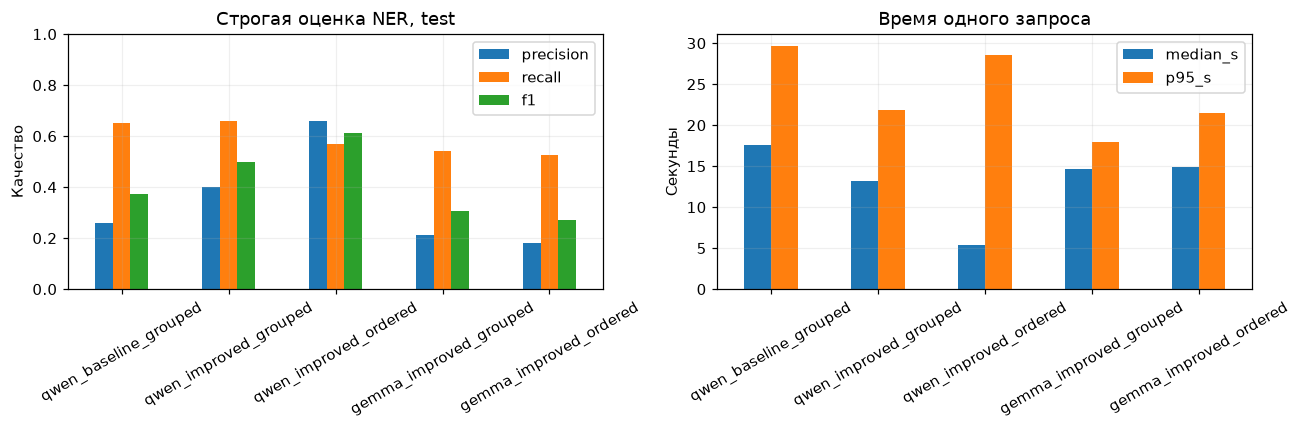

In [ ]:
plot_data = summary[summary["split"] == "test"].set_index("experiment")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_data[["precision", "recall", "f1"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=30)
axes[0].set(title="Строгая оценка NER, test", ylabel="Качество", xlabel="")
timings.reindex(plot_data.index)[["median_s", "p95_s"]].plot.bar(ax=axes[1], rot=30)
axes[1].set(title="Время одного запроса", ylabel="Секунды", xlabel="")
fig.tight_layout()
fig.savefig(FIGURES / "quality_and_time.png")
plt.show()

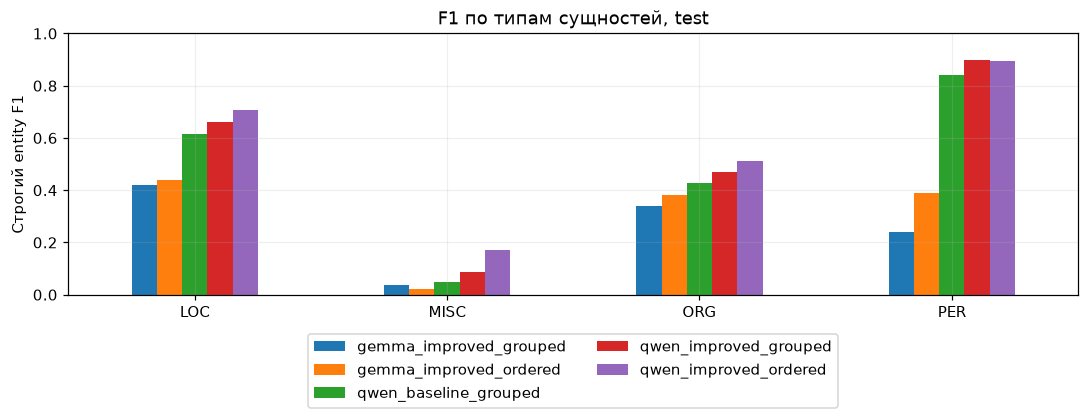

In [ ]:
type_plot = type_metrics.pivot(index="type", columns="experiment", values="f1")
type_plot.plot.bar(ylim=(0, 1), rot=0, figsize=(10, 4))
plt.title("F1 по типам сущностей, test")
plt.ylabel("Строгий entity F1")
plt.xlabel("")
plt.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2)
plt.tight_layout()
plt.savefig(FIGURES / "f1_by_type.png", bbox_inches="tight")
plt.show()

На графиках лидер test по F1 — `qwen_improved_ordered` (0,611); у выбранного по dev варианта `qwen_improved_ordered` F1 для MISC = 0,171, для PER = 0,894, LOC = 0,708, ORG = 0,514. Разница между категориями показывает, почему одной средней метрики недостаточно. p95 характеризует медленные ответы; высокая скорость сама по себе не означает пригодности к автоматическому извлечению.


In [ ]:
def paired_f1_delta(left_name, right_name):
    left = [row for row in all_scored[left_name] if row["split"] == "test"]
    right = [row for row in all_scored[right_name] if row["split"] == "test"]
    assert [row["id"] for row in left] == [row["id"] for row in right]
    a = np.array([[row[key] for key in ["tp", "fp", "fn"]] for row in left])
    b = np.array([[row[key] for key in ["tp", "fp", "fn"]] for row in right])
    rng, deltas = np.random.default_rng(SEED), []
    for _ in range(BOOTSTRAP_SAMPLES):
        ids = rng.integers(0, len(a), len(a))
        deltas.append(prf(*b[ids].sum(axis=0))["f1"] - prf(*a[ids].sum(axis=0))["f1"])
    low, high = np.quantile(deltas, [.025, .975])
    return {"left": left_name, "right": right_name, "low": low, "high": high,
            "delta": prf(*b.sum(axis=0))["f1"] - prf(*a.sum(axis=0))["f1"]}

In [ ]:
comparisons = [("qwen_baseline_grouped", "qwen_improved_grouped"),
               ("qwen_improved_grouped", "qwen_improved_ordered"),
               ("qwen_improved_grouped", "gemma_improved_grouped")]
delta_intervals = pd.DataFrame([paired_f1_delta(*pair) for pair in comparisons])
delta_intervals

,left,right,low,high,delta
0,qwen_baseline_grouped,qwen_improved_grouped,0.073648,0.183372,0.126506
1,qwen_improved_grouped,qwen_improved_ordered,0.021864,0.192332,0.112512
2,qwen_improved_grouped,gemma_improved_grouped,-0.263041,-0.128085,-0.193160


`qwen_baseline_grouped` → `qwen_improved_grouped`: ΔF1 = 0,127, парный 95% bootstrap-интервал [0,074; 0,183]. Интервал не включает ноль, но относится только к выбранным предложениям и конфигурациям.

`qwen_improved_grouped` → `qwen_improved_ordered`: ΔF1 = 0,113, парный 95% bootstrap-интервал [0,022; 0,192]. Интервал не включает ноль, но относится только к выбранным предложениям и конфигурациям.

`qwen_improved_grouped` → `gemma_improved_grouped`: ΔF1 = -0,193, парный 95% bootstrap-интервал [-0,263; -0,128]. Интервал не включает ноль, но относится только к выбранным предложениям и конфигурациям.


## 12. Возможность облачного решения


| Сервис и модель | Бесплатный доступ | Платный API, USD за 1 млн токенов |
|---|---|---|
| Groq, `openai/gpt-oss-20b` | Базовые лимиты: 30 RPM, 1 000 RPD, 8 000 TPM, 200 000 TPD; реальные лимиты уточняются в кабинете | 0,075 вход / 0,30 выход; базовый Developer: 1 000 RPM, 250 000 TPM |
| Gemini, `gemini-3.5-flash-lite` | Вход и выход бесплатны в пределах квот. Конкретные RPM/TPM/RPD показывает AI Studio для проекта | 0,30 вход / 2,50 выход; Batch 0,15 / 1,25 |


Для нового проекта рассматриваем Gemini 3.5 Flash-Lite. В актуальном
[графике поддержки Gemini](https://ai.google.dev/gemini-api/docs/deprecations)
указано, что доступ к серии 2.5 ограничен пользователями, уже работавшими с ней.
Поэтому наличие её старой цены в таблице не означает доступность для нового
аккаунта. Для выбранной 3.5 Flash-Lite дата отключения не объявлена.


In [ ]:
cloud_records = all_records["qwen_improved_ordered"]
estimated_in = math.ceil(sum(len(r["request"]["messages"][0]["content"])
                             for r in cloud_records) / 4)
estimated_out = math.ceil(sum(len(r.get("response", {}).get("message", {})
                                  .get("content", "")) for r in cloud_records) / 4)
budget_in = estimated_in * 2
budget_out = N_SENTENCES * OPTIONS["num_predict"]
display(pd.Series({"requests": N_SENTENCES, "input_char_estimate": estimated_in,
    "output_char_estimate": estimated_out, "input_sensitivity_x2": budget_in,
    "output_budget_tokens": budget_out}))

requests                  100
input_char_estimate     44778
output_char_estimate     3027
input_sensitivity_x2    89556
output_budget_tokens    51200
dtype: int64

Для приближённого расчёта используем четыре символа на токен, включая инструкцию
и схему каждого запроса. Это не точный токенизатор облачной модели и не счёт
за использование API. Верхний сценарий удваивает оценку входа и использует
512 выходных токенов на каждое предложение. Токены внутренних рассуждений,
повторные запросы и служебные накладные расходы могут увеличить расход;
перед запуском нужно получить фактический подсчёт токенов у провайдера.


In [ ]:
cloud_costs = pd.DataFrame([
    {"provider": provider, "free_cost_usd": 0,
     "estimated_paid_usd": (estimated_in * price_in + estimated_out * price_out) / 1e6,
     "sensitivity_paid_usd": (budget_in * price_in + budget_out * price_out) / 1e6}
    for provider, price_in, price_out in
    [("Groq GPT-OSS 20B", .075, .30), ("Gemini 3.5 Flash-Lite", .30, 2.50)]])
groq_lower_min = max(N_SENTENCES / 30, (estimated_in + estimated_out) / 8000)
groq_budget_min = max(N_SENTENCES / 30, (budget_in + budget_out) / 8000)
display(cloud_costs)
display(pd.Series({"Groq_quota_minutes_estimate": groq_lower_min,
    "Groq_quota_minutes_sensitivity": groq_budget_min,
    "Groq_within_daily_token_limit": budget_in + budget_out <= 200_000,
    "Gemini_example_5_RPM_minutes": N_SENTENCES / 5}))

,provider,free_cost_usd,estimated_paid_usd,sensitivity_paid_usd
0,Groq GPT-OSS 20B,0,0.004266,0.022077
1,Gemini 3.5 Flash-Lite,0,0.021001,0.154867


Groq_quota_minutes_estimate       5.975625
Groq_quota_minutes_sensitivity     17.5945
Groq_within_daily_token_limit         True
Gemini_example_5_RPM_minutes          20.0
dtype: object

Для одного прохода по 100 предложениям расчётная платная стоимость: Groq GPT-OSS 20B — $0.0043, чувствительный сценарий — $0.0221; Gemini 3.5 Flash-Lite — $0.0210, чувствительный сценарий — $0.1549. При укладывании в бесплатные квоты стоимость API равна нулю. Это приблизительная оценка токенов, а не фактический счёт или измеренная скорость облачной модели. Для точного планирования нужно проверить квоты аккаунта и токенизацию выбранного API.

Оценка пропускной способности бесплатного Groq даёт около 6,0 мин на один проход; чувствительный сценарий — 17,6 мин. Оба сценария укладываются в указанные дневные лимиты при свободной квоте. Это расчёт по RPM/TPM, а не гарантия времени: задержки, очереди, рассуждения и повторные запросы не измерены. Пример Gemini с 5 RPM даёт 20 мин; фактический лимит нужно посмотреть в AI Studio.


Расчёт относится к **одному проходу по 100 предложениям**, а не ко всем пяти
локальным вариантам. Для повторения всей серии входы, выходы и расходы нужно
суммировать по всем вариантам; бесплатный дневной лимит может потребовать
нескольких дней. Пример 5 RPM для Gemini — сценарий расчёта, а не обещанный
актуальный лимит. Без доступа к кабинету конкретного проекта точное время
бесплатного Gemini определить нельзя.


На бесплатном Gemini вне ЕЭЗ, Швейцарии и Великобритании входы и ответы могут
использоваться для улучшения продуктов, включая обработку людьми. В указанных
регионах действуют условия обработки платного сервиса даже для бесплатного
использования. Платный Gemini не использует входы и ответы для улучшения
продуктов, но предусматривает ограниченное хранение для контроля нарушений.
См. [условия Gemini](https://ai.google.dev/gemini-api/terms).

Groq запрещает обучение на входах и ответах без явного разрешения клиента
([соглашение](https://console.groq.com/docs/legal/services-agreement)).
При обычном inference данные по умолчанию не сохраняются; возможны логи
надёжности/злоупотреблений до 30 дней. Есть настройка ZDR; batch хранит файлы
до 30 дней. См. [обработку данных Groq](https://console.groq.com/docs/your-data).

Нужны учётная запись и API-ключ, соблюдение условий датасета и доступность
сервиса в регионе. Для Gemini нужно свериться со
[списком регионов](https://ai.google.dev/gemini-api/docs/available-regions):
доступ нельзя считать универсальным. В данном исследовании аккаунты не
создавали, ключи не использовали и фактическую доступность API не проверяли.


Облако практичнее для небольших нерегулярных партий при доступном API,
разрешённой передаче данных и ограниченном локальном оборудовании.
Бесплатный тариф удобен для пилота, но квоты, очереди, смена моделей и условия
обработки данных делают его слабой гарантией для production. Для стабильной
нагрузки следует оценивать платный API и обработку ошибок 429 с backoff.
Локальная модель удобнее для работы без сети, контроля версии и места обработки.
Высокое облачное качество здесь не доказано: облачные модели потребуют той же
оценки NER и MISC на размеченных текстах.


## 13. Выводы и ограничения


Среди исследованных конфигураций для прототипа выбираем
**Qwen 3 4B Instruct с уточнённой инструкцией и единым списком**. Выбор сделан
по dev (F1 = 0,636); на test Precision = 0,658, Recall = 0,570, F1 = 0,611.
На всех 100 предложениях описательный F1 = 0,618. Один проход занял 18,8 мин;
медиана запроса — 5,34 с, p95 — 28,62 с. Оценка занятого моделью объёма
Ollama — 3,26 GiB, CPU-режим. Список уменьшил лишние сущности, но часть
полноты была потеряна, а порядок требует отдельной проверки.

Gemma 3 1B уменьшила этот объём до 1,12 GiB, однако test F1 составил 0,305
при группировке и 0,271 при списке, а медианы — 14,65 и 14,87 с.
В этих условиях сопоставимого качества или выигрыша по времени не получено;
меньшее число параметров само по себе не гарантирует меньшую задержку.
Это сравнение конкретных семейств, инструкции и реализации в Docker.

Для полностью автоматического извлечения всех четырёх типов качество
недостаточно: у выбранного варианта только 7 из 62 непустых test-предложений
полностью совпали с gold; F1 MISC = 0,171. PER заметно лучше (F1 = 0,894),
но результат нельзя переносить на документы компании без новой оценки.
Модель можно использовать как помощника для разметки с проверкой человеком.
В программной системе нужны Pydantic-валидация, проверка фрагментов по тексту,
контроль дублей, конфликтующих типов и порядка, а также явная обработка
обрыва ответа. Эти проверки не заменяют оценку смысловой правильности.

Облачный API может быть практичнее для небольших нерегулярных партий при
доступности в регионе и допустимых условиях обработки данных: расчётная
стоимость одного прохода очень мала. Его качество NER здесь не измерено.
Локальный вариант сохраняет контроль над данными и версией модели и работает
без сети после загрузки весов. Схема задаёт интерфейс результата; правильность
сущностей определяется моделью, инструкцией, контекстом и принятой разметкой.


100 предложений — небольшая случайная выборка англоязычных новостей и
спортивных/финансовых строк CoNLL. В ней нет русскоязычных текстов и документов
компании; результаты на них могут отличаться. Редкая MISC имеет мало примеров.
Внутренние dev/test взяты из train, возможны общие статьи и попадание известного
публичного корпуса в предобучение LLM. Изоляция предложений лишает модель контекста.

BIO — эталон выбранного корпуса, а не универсальная истина. Встречаются спорные
типы, непоследовательные границы и названия без разметки. Мы не меняли gold по
ответам модели. Строгое сравнение чувствительно к восстановлению пробелов.
Результат без offsets неоднозначен для одинаковых повторных упоминаний.

Измерения относятся к двум квантованным моделям, заданной инструкции, одному
seed, CPU Docker, четырём потокам и конкретной версии Ollama. Один запрос на
предложение не измеряет вариативность ответов и нагрузку с конкуренцией.
Температура 0 уменьшает случайность, но не гарантирует идентичность на другом
оборудовании. Bootstrap оценивает только вариативность этой выборки и не
учитывает зависимость предложений внутри статей. Нет сравнения с обученной NER,
нет испытания prompt injection, длинных документов и отказов production.

Тарифы, квоты и модели облачных сервисов меняются. Расчёт стоимости приблизителен,
не включает электричество, амортизацию, разработку и эксплуатацию локального сервиса.
Гарантия схемы не заменяет проверку качества и правила обработки недостоверных
предсказаний в программной системе.

Уточнённая инструкция выведена по dev Qwen и перенесена в Gemma без отдельной настройки под её семейство. Сравниваем эти общие условия, а не максимальное достижимое качество каждой модели. Последовательные проходы не контролируют весь фоновый шум системы; длина ответов и повторное использование общего префикса Ollama также влияют на время. В gold нет повторов одинакового полного упоминания внутри предложения: такие повторы проверены только синтетически. У трёх gold-строк (Bistrita, California, Israel) есть несколько буквальных позиций, в том числе внутри более длинного названия. Восстановление позиций слева направо здесь является соглашением оценивания, а не ответом модели.


In [ ]:
summary.to_csv(RESULTS / "summary.csv", index=False)
type_metrics.to_csv(RESULTS / "metrics_by_type.csv", index=False)
timings.to_csv(RESULTS / "timings.csv")
runtime.to_csv(RESULTS / "request_timings.csv", index=False)
delta_intervals.to_csv(RESULTS / "paired_f1_intervals.csv", index=False)
cloud_costs.to_csv(RESULTS / "cloud_cost_estimate.csv", index=False)
save_json(RESULTS / "model_metadata.json", model_metadata)
save_json(RESULTS / "prompts.json", {"baseline": BASE_PROMPT, "improved": IMPROVED_PROMPT,
          "grouped": GROUP_INSTRUCTION, "ordered": ORDER_INSTRUCTION})
save_json(RESULTS / "all_scores.json", all_scored)
print("Таблицы, ответы, ошибки, метаданные, инструкции и графики сохранены.")

Таблицы, ответы, ошибки, метаданные, инструкции и графики сохранены.


In [ ]:
assert len(inputs) == 100 and len(gold) == 100
assert all(len(records) == 100 for records in all_records.values())
for records in all_records.values():
    for record in records:
        request = record["request"]
        expected_request = make_request(input_by_id[record["id"]]["text"],
            request["model"], BASE_PROMPT if record["experiment"] ==
            "qwen_baseline_grouped" else IMPROVED_PROMPT, record["format"])
        assert request == expected_request
        assert set(request) == {"model", "messages", "format", "stream", "options", "keep_alive"}
assert data_hashes == {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
                       for name in data_hashes}
print("5 × 100 ответов; gold не включён в запросы; исходные данные не изменены.")
client.close()

5 × 100 ответов; gold не включён в запросы; исходные данные не изменены.


Ноутбук и все результаты сохраняются в `work`. Для полного повторения
запустить `docker compose up --build`, открыть Jupyter и выполнить ячейки сверху
вниз. Существующий кэш предотвращает повторную генерацию; для новых ответов
изменить `REFRESH_RESPONSES` на `True`. После работы сохранить ноутбук и
выполнить `docker compose down`. Именованный том Ollama сохраняется: повторно
скачивать модели не потребуется.
